<a href="https://colab.research.google.com/github/VidhyaSriKS/AIML-assignment/blob/main/Energy_Consumption.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# World Energy Consumption Forecasting
This notebook demonstrates a complete end-to-end pipeline to predict a country's future energy consumption using historical data and an LSTM deep learning model.

## 1. Setup & Environment Preparation
Ensure the required libraries are installed and imported properly.

In [ ]:
from google.colab import files
import os

# Open file upload interface
uploaded = files.upload()

# Verify upload and find filename
if uploaded:
    uploaded_filename = list(uploaded.keys())[0]
    print(f"Successfully uploaded: {uploaded_filename}")

Saving World_Energy_By_Country_And_Region_1965_to_2023.csv to World_Energy_By_Country_And_Region_1965_to_2023 (1).csv
Successfully uploaded: World_Energy_By_Country_And_Region_1965_to_2023 (1).csv


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

## 2. Load and Inspect the Dataset
Load the dataset, inspect the shape, column names, and missing values.

In [ ]:
# Locate our dataset file
csv_files = [f for f in os.listdir('.') if f.endswith('.csv')]
if csv_files:
    filename = csv_files[0]
    df = pd.read_csv(filename)
    print(f"Loaded: {filename}")
    print("Shape:", df.shape)
    print("\nMissing values per column (Preview):\n", df.isnull().sum().head(10))
else:
    print("Dataset CSV file not found in current directory. Please upload the file.")

Loaded: World_Energy_By_Country_And_Region_1965_to_2023 (1).csv
Shape: (111, 60)

Missing values per column (Preview):
 Country    8
1965       8
1966       8
1967       8
1968       8
1969       8
1970       8
1971       8
1972       8
1973       8
dtype: int64


## 3. Data Cleaning, Melt, and Interpolation
Select a country (e.g., Canada), reshape the table into a time series format, sort it chronologically, and resolve missing values.

In [ ]:
# Clean rows and columns
df_cleaned = df.dropna(how="all")
df_cleaned = df_cleaned.dropna(subset=["Country"])

# Reshape dataset from wide to long format
data = df_cleaned.melt(
    id_vars=["Country"],
    var_name="Year",
    value_name="Energy_Consumption"
)

# Parse types
data["Year"] = pd.to_numeric(data["Year"], errors="coerce")
data["Energy_Consumption"] = pd.to_numeric(data["Energy_Consumption"], errors="coerce")
data = data.dropna(subset=["Year"])
data["Year"] = data["Year"].astype(int)

# Filter for Canada
country_name = "Canada"
data_country = data[data["Country"] == country_name].copy()
data_country = data_country.sort_values("Year")

# Handle missing values chronologically
data_country = data_country.set_index("Year")
all_years = range(data_country.index.min(), data_country.index.max() + 1)
data_country = data_country.reindex(all_years)
data_country.index.name = "Year"

# Interpolate any missing data points internally
data_country["Energy_Consumption"] = data_country["Energy_Consumption"].interpolate(method="linear", limit_area="inside")
data_country = data_country.dropna(subset=["Energy_Consumption"]).reset_index()

print(f"Cleaned data for {country_name}:")
display(data_country.head(10))

Cleaned data for Canada:


,Year,Country,Energy_Consumption
0,1965,Canada,5.00
1,1966,Canada,5.32
2,1967,Canada,5.57
3,1968,Canada,5.92
4,1969,Canada,6.28
5,1970,Canada,6.73
6,1971,Canada,6.94
7,1972,Canada,7.47
8,1973,Canada,8.11
9,1974,Canada,8.36


## 4. Normalization and Splitting
Split the data into training (80%) and test (20%) sets chronologically to avoid look-ahead bias, apply scaling, and create 5-year sliding sequences.

In [ ]:
# Chronological split based on index
values = data_country["Energy_Consumption"].values.reshape(-1, 1)
split = int(len(values) * 0.8)

# Normalize data based on training scaling limits
scaler = MinMaxScaler()
scaler.fit(values[:split])
scaled_values = scaler.transform(values)

# Create historical 5-year sequences to predict next year
window = 5
X, y, target_indices = [], [], []

for i in range(window, len(scaled_values)):
    X.append(scaled_values[i - window : i])
    y.append(scaled_values[i])
    target_indices.append(i)

X = np.array(X)
y = np.array(y)
target_indices = np.array(target_indices)

# Final Train/Test splits
train_mask = target_indices < split
test_mask = target_indices >= split

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Data shape summaries:")
print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}  | y_test:  {y_test.shape}")

Data shape summaries:
X_train: (42, 5, 1) | y_train: (42, 1)
X_test:  (12, 5, 1)  | y_test:  (12, 1)


## 5. Model Architecture & Training
We select an **LSTM (Long Short-Term Memory)** neural network because it effectively retains temporal patterns over long periods, resolving the vanishing gradient problems associated with traditional RNN architectures.
We train the model with an early stopping routine.

In [ ]:
# Build LSTM Model
model = Sequential([
    Input(shape=(window, 1)),
    LSTM(32),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(optimizer="adam", loss="mean_squared_error")

early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

# Fit Model
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 224ms/step - loss: 0.3767 - val_loss: 0.7937
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.3065 - val_loss: 0.6696
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.2615 - val_loss: 0.5765
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.2121 - val_loss: 0.4467
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.1442 - val_loss: 0.2837
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0755 - val_loss: 0.1409
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0259 - val_loss: 0.0459
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0040 - val_loss: 0.0051
Epoch 9/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0058 - val_loss: 0.0017
Epoch 10/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0135 - val_loss: 0.0033
Epoch 11/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0132 - val_loss: 0.0010
Epoch 12/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0084 - val_l

## 6. Model Evaluation and Visualization
Invert the scaling on the predicted targets to calculate true Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE), and plot the final predictions.

Mean Absolute Error (MAE): 0.2847
Root Mean Squared Error (RMSE): 0.3585


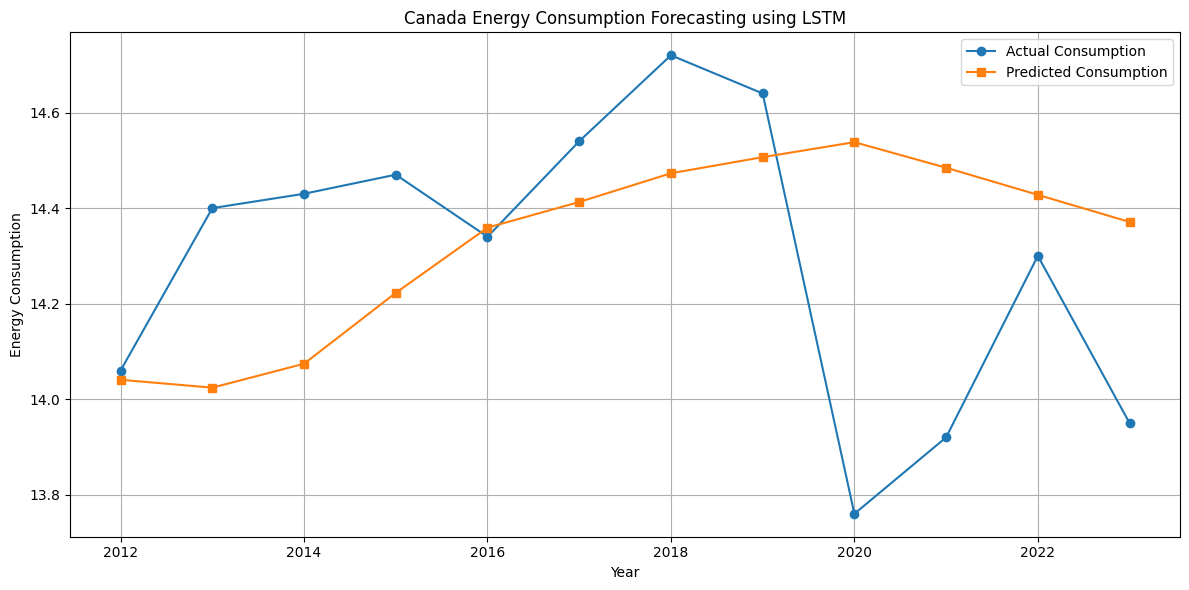

,Year,Actual,Predicted
0,2012,14.06,14.040596
1,2013,14.40,14.024090
2,2014,14.43,14.074145
3,2015,14.47,14.222539
4,2016,14.34,14.359111
5,2017,14.54,14.412786
6,2018,14.72,14.472946
7,2019,14.64,14.506618
8,2020,13.76,14.538043
9,2021,13.92,14.484551


In [ ]:
# Generate predictions on the test dataset
pred_scaled = model.predict(X_test, verbose=0)

# Rescale back to actual energy metrics
actual = scaler.inverse_transform(y_test)
predicted = scaler.inverse_transform(pred_scaled)

# Calculate and display metrics
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
print("Mean Absolute Error (MAE):", round(mae, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))

# Generate Visualizations
test_years = data_country["Year"].values[target_indices[test_mask]]

plt.figure(figsize=(12, 6))
plt.plot(test_years, actual.flatten(), marker="o", color="tab:blue", label="Actual Consumption")
plt.plot(test_years, predicted.flatten(), marker="s", color="tab:orange", label="Predicted Consumption")
plt.title(f"{country_name} Energy Consumption Forecasting using LSTM")
plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Tabulate actual vs predicted results
results = pd.DataFrame({
    "Year": test_years,
    "Actual": actual.flatten(),
    "Predicted": predicted.flatten()
})
display(results)

## 7. Compute Accuracy Metrics for Regression
Since standard accuracy is for classification, we compute alternative metrics including Mean Absolute Percentage Error (MAPE), overall forecast percentage accuracy, R-squared ($R^2$), and a threshold-based tolerance accuracy (predictions within $10\%$ of actual values).

In [ ]:
from sklearn.metrics import r2_score

# 1. Mean Absolute Percentage Error (MAPE)
mape = np.mean(np.abs((actual - predicted) / actual)) * 100

# 2. Overall Forecast Accuracy
forecast_accuracy = 100 - mape

# 3. R-squared (R2) Score
r2 = r2_score(actual, predicted)

# 4. Threshold Accuracy (Percentage of predictions within 10% of actual values)
percentage_errors = np.abs((actual - predicted) / actual)
tolerance = 0.10  # 10% threshold
within_tolerance = np.mean(percentage_errors <= tolerance) * 100

print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")
print(f"Overall Forecast Accuracy (100 - MAPE): {forecast_accuracy:.2f}%")
print(f"R-squared (R2) Score: {r2:.4f}")
print(f"Accuracy within 10% Tolerance: {within_tolerance:.2f}%")

Mean Absolute Percentage Error (MAPE): 2.01%
Overall Forecast Accuracy (100 - MAPE): 97.99%
R-squared (R2) Score: -0.5084
Accuracy within 10% Tolerance: 100.00%
